# Лабораторная работа № 4. Визуализация кривых второго порядка и поверхностей


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

np.set_printoptions(precision=5, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Канонические кривые второго порядка

Для начала строятся три базовые кривые.

Эллипс:

$$
\frac{x^2}{a^2}+\frac{y^2}{b^2}=1,
\qquad
x=a\cos t,\quad y=b\sin t.
$$

Гипербола:

$$
\frac{x^2}{a^2}-\frac{y^2}{b^2}=1,
\qquad
x=a\cosh t,\quad y=b\sinh t.
$$

Эта параметризация задаёт правую ветвь. Левая ветвь получается изменением знака
$x$.

Парабола:

$$
y^2=2px,
\qquad
x=\frac{t^2}{2p},\quad y=t.
$$

При построении важно самостоятельно выбрать разумный диапазон параметра: он должен
показывать всю интересующую область кривой, но не приводить к неоправданно большим
значениям координат.

In [2]:
def ellipse_points(a, b, n=500):
    # TODO: сформировать массив параметров t и вернуть x, y эллипса
    t = np.linspace(0, 2 * np.pi, n)
    x_par = lambda t: a * np.cos(t)
    y_par = lambda t: b * np.sin(t)

    x, y = x_par(t), y_par(t)
    return x, y

def hyperbola_points(a, b, t_min=-1.5, t_max=1.5, n=500):
    # TODO: сформировать параметр t
    # TODO: вычислить правую ветвь гиперболы
    # TODO: получить левую ветвь изменением знака x
    # TODO: вернуть x_right, y_right, x_left, y_left
    t = np.linspace(t_min, t_max, n)
    
    x_par = lambda t: a * np.cosh(t)
    y_par = lambda t: b * np.sinh(t)

    x_right, y_right = x_par(t), y_par(t)
    x_left, y_left = -x_par(t), y_par(t)

    return x_right, y_right, x_left, y_left


def parabola_points(p, t_min=-4, t_max=4, n=500):
    # TODO: сформировать параметр t и вычислить x, y
    t = np.linspace(t_min, t_max, n)

    x_par = lambda t: t ** 2 / (2 * p)
    y_par = lambda t: t

    x, y = x_par(t), y_par(t)
    
    return x, y

### Задание 1. Построение кривых

1. Реализуйте три функции выше.
2. Постройте на одной координатной плоскости:
   - эллипс с $a=3,\ b=2$;
   - обе ветви гиперболы с $a=3,\ b=2$;
   - параболу $y^2=4x$.
3. Добавьте оси координат, сетку, подписи и легенду.
4. Используйте одинаковый масштаб по осям.
5. Проверьте, что построенные точки действительно удовлетворяют соответствующим
   каноническим уравнениям.

Для проверки можно вычислить максимальную абсолютную невязку между левой и правой
частями уравнения.

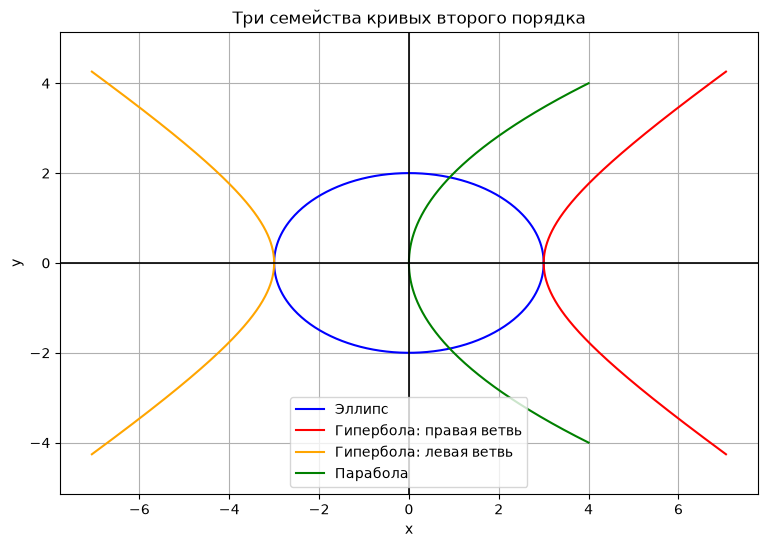

In [3]:
a, b = 3.0, 2.0
p = 2.0

# TODO: получить точки трёх кривых
x_e, y_e = ellipse_points(a, b)
x_h_r, y_h_r, x_h_l, y_h_l = hyperbola_points(a, b)
x_p, y_p = parabola_points(p)

# TODO: построить все кривые на одном графике

plt.figure(figsize=(9, 6))
plt.plot(x_e, y_e, label="Эллипс", color='blue')
plt.plot(x_h_r, y_h_r, label="Гипербола: правая ветвь", color='red')
plt.plot(x_h_l, y_h_l, label="Гипербола: левая ветвь", color='orange')
plt.plot(x_p, y_p, label="Парабола", color='green')
plt.axhline(0, linewidth=1.2, color='black')
plt.axvline(0, linewidth=1.2, color='black')
plt.axis("equal")
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Три семейства кривых второго порядка")
plt.legend()
plt.show()

In [4]:
# Проверка канонических уравнений.
# После реализации функций замените TODO на ваши массивы.

ellipse_residual = np.max(np.abs(x_e**2 / a**2 + y_e**2 / b**2 - 1))
hyperbola_residual = np.max(np.abs(x_h_r**2 / a**2 - y_h_r**2 / b**2 - 1))
parabola_residual = np.max(np.abs(y_p**2 - 2*p*x_p))

print("Невязка эллипса:", ellipse_residual)
print("Невязка гиперболы:", hyperbola_residual)
print("Невязка параболы:", parabola_residual)

Невязка эллипса: 2.220446049250313e-16
Невязка гиперболы: 1.7763568394002505e-15
Невязка параболы: 0.0


## 2. Преобразования координат

Для преобразований плоских фигур используются однородные координаты:

$$
\mathbf p=
\begin{pmatrix}
x\\y\\1
\end{pmatrix}.
$$

Перенос:

$$
T(t_x,t_y)=
\begin{pmatrix}
1&0&t_x\\
0&1&t_y\\
0&0&1
\end{pmatrix}.
$$

Масштабирование:

$$
S(s_x,s_y)=
\begin{pmatrix}
s_x&0&0\\
0&s_y&0\\
0&0&1
\end{pmatrix}.
$$

Поворот:

$$
R(\varphi)=
\begin{pmatrix}
\cos\varphi&-\sin\varphi&0\\
\sin\varphi&\cos\varphi&0\\
0&0&1
\end{pmatrix}.
$$

Если сначала выполняется преобразование $M_1$, а затем $M_2$, то

$$
\mathbf p_{\text{new}}=M_2M_1\mathbf p.
$$

Правая матрица действует первой.

In [5]:
def translation_matrix(tx, ty):
    # TODO: вернуть матрицу переноса 3x3
    matrix = np.eye(3)
    matrix[0, 2] = tx
    matrix[1, 2] = ty

    return matrix


def scaling_matrix(sx, sy):
    # TODO: вернуть матрицу масштабирования 3x3
    matrix = np.eye(3)
    matrix[0, 0] = sx
    matrix[1, 1] = sy

    return matrix


def rotation_matrix(phi):
    # TODO: вернуть матрицу поворота 3x3
    return np.array([
        [np.cos(phi), -np.sin(phi), 0],
        [np.sin(phi), np.cos(phi), 0],
        [0, 0, 1]
    ])


def apply_transform(points, M):
    # TODO: проверить совместимость размеров и выполнить M @ points
    if points.shape[0] != 3:
        raise ValueError("Введите точки в координатах $R_{3}$")
    if M.shape != (3, 3):
        raise ValueError("Матрица преобразования для $R_{3}$ должна быть квадратной 3x3")

    return M @ points


def ellipse_points_homogeneous(a, b, n=500):
    t = np.linspace(0, 2 * np.pi, n)
    return np.vstack((
        a * np.cos(t),
        b * np.sin(t),
        np.ones_like(t)
    ))

### Задание 2. Перенос, поворот и масштабирование

Реализуйте четыре функции выше.

Для эллипса из задания 1 выполните последовательно:

1. масштабирование в $1.5$ раза по $x$ и в $0.75$ раза по $y$;
2. поворот на $\varphi=\pi/6$;
3. перенос на $(2,-1)$.

Постройте исходный и преобразованный эллипсы на одном графике.

В коде явно сформируйте общую матрицу преобразования. Проверьте её действие хотя бы
на одной точке вручную.

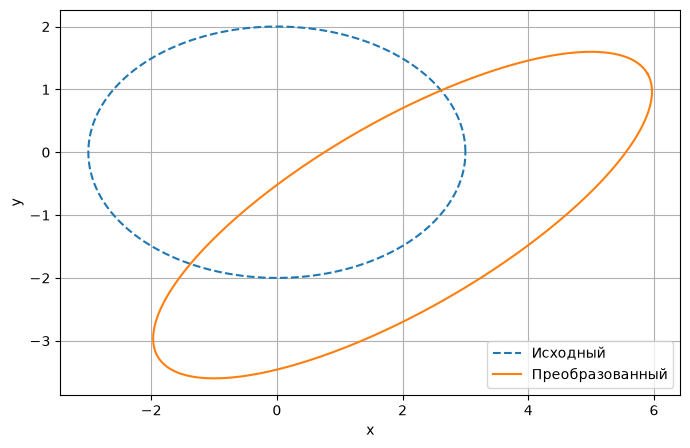

In [6]:
points = ellipse_points_homogeneous(3, 2)

S = scaling_matrix(1.5, 0.75)
R = rotation_matrix(np.pi / 6)
T = translation_matrix(2, -1)

# Справа действует первая матрица.
# TODO: сформировать общую матрицу M
M = T @ R @ S

# TODO: применить преобразование
transformed = apply_transform(points, M)

# TODO: построить исходный и преобразованный эллипсы
plt.plot(points[0], points[1], label='Исходный', linestyle='--')
plt.plot(transformed[0], transformed[1], label='Преобразованный')
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

## 3. Порядок преобразований

Матрицы преобразований в общем случае не коммутируют:

$$
TR\ne RT.
$$

Это означает, что результат зависит от порядка действий. Например, если сначала
перенести эллипс, а затем повернуть его, поворот будет происходить уже вокруг начала
координат, а не вокруг нового центра эллипса.

### Задание 3. Сравнение порядка преобразований

Используйте один и тот же эллипс и две последовательности:

- поворот $\rightarrow$ перенос;
- перенос $\rightarrow$ поворот.

Постройте оба результата вместе с исходным эллипсом.

Дополнительно выберите одну точку эллипса и покажите численно, что две
последовательности дают разные координаты.

Исходная точка: 3.0, 0.0
Поворот --> Перенос: 4.598076211353316, 2.5
Перенос --> Поворот: 3.8301270189221936, 3.3660254037844384


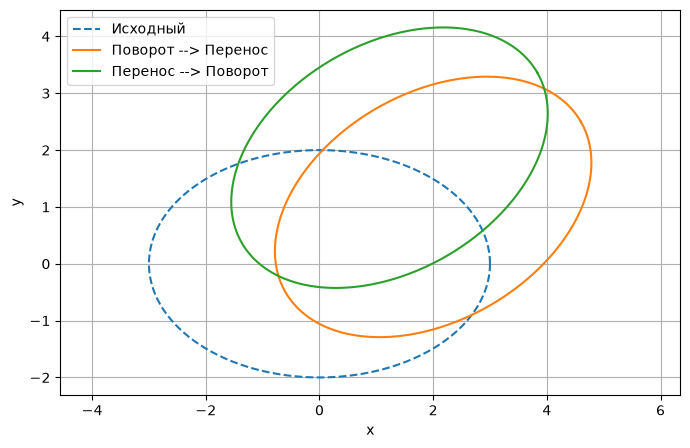

In [7]:
points = ellipse_points_homogeneous(3, 2)

R = rotation_matrix(np.pi / 6)
T = translation_matrix(2, 1)

# TODO: получить две последовательности преобразований
curve_rotate_then_shift = apply_transform(points, T @ R)
curve_shift_then_rotate = apply_transform(points, R @ T)

# TODO: выбрать одну точку и сравнить результаты
point = points[:, 0]
result_1 = curve_rotate_then_shift[:, 0]
result_2 = curve_shift_then_rotate[:, 0]
print(f'Исходная точка: {point[0]}, {point[1]}')
print(f'Поворот --> Перенос: {result_1[0]}, {result_1[1]}')
print(f'Перенос --> Поворот: {result_2[0]}, {result_2[1]}')

# TODO: построить три кривые
plt.plot(points[0], points[1], label='Исходный', linestyle='--')
plt.plot(curve_rotate_then_shift[0], curve_rotate_then_shift[1], label='Поворот --> Перенос')
plt.plot(curve_shift_then_rotate[0], curve_shift_then_rotate[1], label='Перенос --> Поворот')
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

В отчёте объясните наблюдаемое различие не только словами, но и с точки зрения
матричного произведения: какая матрица действует первой в каждом случае?

Правая матрица подействует первойРазличие на графике демонстрирует, что операции поворота и переноса не коммутируют между собой. В матричном произведении $M=A * B$, где $A$ и $B$ -- матрицы преобразований, первой к объекту применяется матрица BB, так как умножение вектора на матрицу происходит справа налево. В случае $T * R$ первой работает матрица поворота, в случае $R * T$ -- матрица переноса, что и дает принципиально разные итоговые координаты.


## 4. Общее уравнение кривой второго порядка

Для своего варианта используется уравнение

$$
Ax^2+Bxy+Cy^2+Dx+Ey+F=0.
$$

Тип кривой предварительно определяется по дискриминанту

$$
\Delta=B^2-4AC.
$$

Для невырожденных кривых:

- $\Delta<0$ — эллиптический тип;
- $\Delta=0$ — параболический тип;
- $\Delta>0$ — гиперболический тип.

Однако вычисления на этом не заканчиваются. Необходимо показать, как исходное уравнение
связано с канонической формой.

Для эллипса и гиперболы сначала можно найти центр из системы

$$
\begin{cases}
2Ax_0+By_0+D=0,\\
Bx_0+2Cy_0+E=0.
\end{cases}
$$

После переноса в центр остаётся квадратичная часть. Поворот координат позволяет
устранить член $XY$.

Угол поворота связан с коэффициентами квадратичной части соотношением

$$
\tan 2\theta=\frac{B}{A-C}.
$$

В программной реализации удобно использовать более устойчивую запись через `arctan2`:

```python
theta = 0.5 * np.arctan2(B, A - C)
```

При выборе другого эквивалентного угла могут поменяться местами оси $X$ и $Y$, но
полученная каноническая кривая останется той же.

Для параболы $\Delta=0$: после поворота осей член $XY$ также устраняется, после чего
линейной заменой координат уравнение приводится к параболическому виду.

In [8]:
# Введите коэффициенты СВОЕГО варианта.
A = 16.0
B = -24.0
C = 9.0
D = -84.0
E = -62.0
F = -71.0

delta = B ** 2 - 4 * A * C
print("Δ =", delta)

if delta < 0:
    print("Эллиптический тип")
elif np.isclose(delta, 0):
    print("Параболический тип")
else:
    print("Гиперболический тип")

Δ = 0.0
Параболический тип


### Задание 4. Приведение кривой своего варианта к каноническому виду

Для выданного варианта:

1. выпишите коэффициенты $A,B,C,D,E,F$;
2. вычислите $\Delta$ и определите тип кривой;
3. аналитически выполните необходимые преобразования координат:
   - перенос;
   - поворот, если требуется;
   - выделение канонической формы;
4. запишите полученное каноническое уравнение;
5. укажите характерные параметры кривой: центр, полуоси, вершину, направление ветвей
   или другие параметры, соответствующие вашему типу;
6. построите исходную кривую как линию уровня
   $F(x,y)=0$ с помощью `contour`;
7. отдельно задайте кривую в канонических координатах и выполните обратное
   преобразование, чтобы получить её в исходной системе координат;
8. нанесите оба результата на один график.

Идея последней проверки: аналитически преобразованная кривая и исходное уравнение
должны совпадать на графике.

In [9]:
theta = 0.5 * np.arctan2(B, A - C)
R = rotation_matrix(theta)

U = np.array([
    [A, B / 2],
    [B / 2, C]
])

U_new = R[:2, :2].T @ U @ R[:2, :2]
A_new, C_new = U_new[0, 0], U_new[1, 1]
D_new, E_new = np.array([D, E]) @ R[:2, :2]

if np.abs(A_new) > np.abs(C_new): # Проверка при какой переменной остался ненулевой квадратичный коэффициент
    shift_x = -D_new / (2 * A_new)
    shift_y = -(F - D_new ** 2 / (4 * A_new)) / E_new

    p = -E_new / (2 * A_new)
    along_y = True
else:
    shift_y = -E_new / (2 * C_new)
    shift_x = -(F - E_new ** 2 / (4 * C_new)) / D_new

    p = -D_new / (2 * C_new)
    along_y = False


T = translation_matrix(shift_x, shift_y)
M = R @ T  # канон --> исходные

Вообще можно было искать `A_new` и `B_new` c помошью `lambdas, _ = linalg.eig(U)`

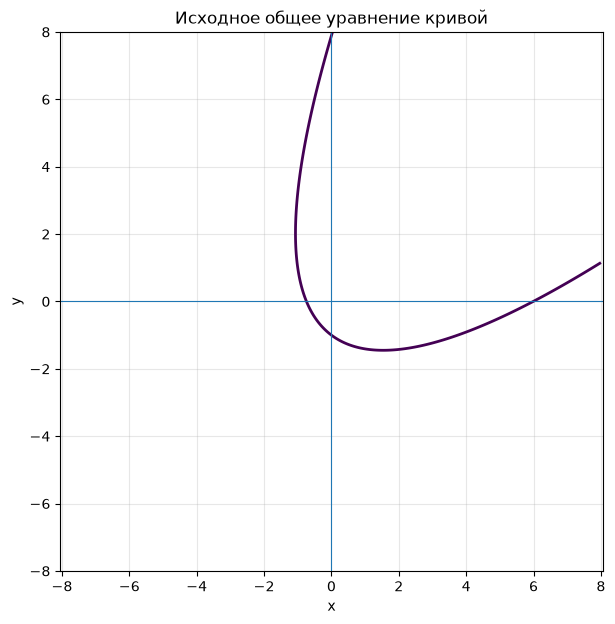

In [10]:
def conic_value(X, Y, A, B, C, D, E, F):
    return A*X**2 + B*X*Y + C*Y**2 + D*X + E*Y + F


# Сетка для построения неявной кривой.
x = np.linspace(-8, 8, 600)
y = np.linspace(-8, 8, 600)
X, Y = np.meshgrid(x, y)

Z = conic_value(X, Y, A, B, C, D, E, F)

plt.figure(figsize=(7, 7))
plt.contour(X, Y, Z, levels=[0], linewidths=2)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Исходное общее уравнение кривой")
plt.show()

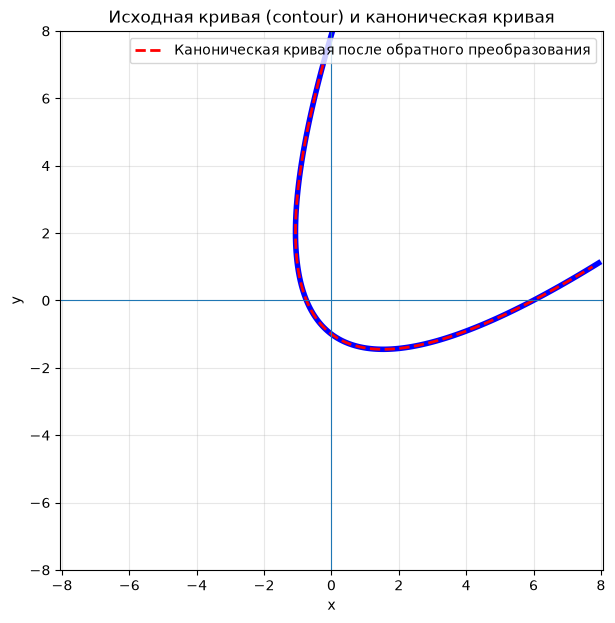

In [11]:
# Здесь задаётся КАНОНИЧЕСКАЯ кривая вашего варианта.
# Аналитические параметры (центр, угол, полуоси, p и т. д.)
# должны быть найдены в ходе задания 4.
# TODO: сформировать точки канонической кривой.
t = np.linspace(-5, 5, 600)
if along_y:
    canonical_points = np.array([t, t ** 2 / (2 * p), np.ones_like(t)])
else:
    canonical_points = np.array([t ** 2 / (2 * p), t, np.ones_like(t)])

# TODO: выполнить обратное преобразование и получить точки
# в исходной системе координат.
transformed_points = apply_transform(canonical_points, M)

# TODO: построить исходную кривую contour и преобразованную параметрическую кривую
plt.figure(figsize=(7, 7))
plt.contour(X, Y, Z, levels=[0], linewidths=4, colors='blue')
plt.plot(transformed_points[0], transformed_points[1], "--", color='red',
         linewidth=2, label="Каноническая кривая после обратного преобразования")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Исходная кривая (contour) и каноническая кривая")
plt.legend()
plt.show()

In [12]:
# Численная проверка полученной параметризации.
# После реализации transformed_points вычислите максимальную невязку:

x_t = transformed_points[0]
y_t = transformed_points[1]
residual = np.max(np.abs(
    conic_value(x_t, y_t, A, B, C, D, E, F)
))
print("Максимальная невязка:", residual)

Максимальная невязка: 2.2737367544323206e-13


## 5. Поверхности второго порядка

Теперь двумерные кривые расширяются до трёхмерного случая.

Для поверхности нужно получить сетку параметров и вычислить для каждой пары параметров
координаты $(x,y,z)$.

### Эллипсоид

$$
\frac{x^2}{a^2}+\frac{y^2}{b^2}+\frac{z^2}{c^2}=1.
$$

Параметризация:

$$
x=a\sin u\cos v,
$$

$$
y=b\sin u\sin v,
$$

$$
z=c\cos u,
$$

где

$$
u\in[0,\pi],\qquad v\in[0,2\pi].
$$

### Однополостный гиперболоид

$$
\frac{x^2}{a^2}+\frac{y^2}{b^2}-\frac{z^2}{c^2}=1.
$$

Удобная параметризация:

$$
x=a\cosh u\cos v,\qquad
y=b\cosh u\sin v,\qquad
z=c\sinh u.
$$

### Эллиптический параболоид

$$
z=\frac{x^2}{a^2}+\frac{y^2}{b^2}.
$$

Для него удобно сначала построить сетку $X,Y$, а затем вычислить $Z$.

### Задание 5. Эллипсоид

Постройте эллипсоид с полуосями

$$
a=3,\qquad b=2,\qquad c=1.
$$

Требования:

1. использовать параметрическое задание;
2. применить `np.meshgrid`;
3. использовать `plot_surface`;
4. добавить подписи всех осей и заголовок;
5. выбрать информативный угол обзора;
6. добавить цветовую шкалу.

Проверьте, что поверхность действительно замкнута и имеет ожидаемые размеры по трём
координатам.

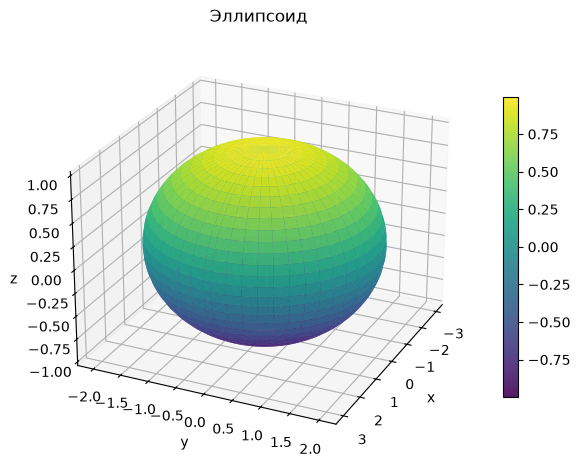

In [13]:
a, b, c = 3.0, 2.0, 1.0

u = np.linspace(0, np.pi, 60)
v = np.linspace(0, 2 * np.pi, 100)

# TODO: создать U, V с помощью meshgrid
U, V = np.meshgrid(u, v)

# TODO: вычислить X, Y, Z
X = a * np.sin(U) * np.cos(V)
Y = b * np.sin(U) * np.sin(V)
Z = c * np.cos(U)

# TODO: построить поверхность
fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Эллипсоид")
ax.view_init(elev=25, azim=25)
plt.colorbar(surf, ax=ax, shrink=0.65)
plt.show()

### Задание 6. Гиперболоид и параболоид

Постройте:

1. однополостный гиперболоид с $a=2,\ b=1.5,\ c=1$;
2. эллиптический параболоид

$$
z=\frac{x^2}{4}+\frac{y^2}{9}.
$$

Для каждого объекта:

- используйте отдельный 3D-график;
- подпишите оси;
- добавьте заголовок;
- используйте цветовую шкалу;
- выберите такой масштаб и угол обзора, чтобы форма поверхности была хорошо видна.

Для гиперболоида используйте параметрическую сетку. Для параболоида используйте
`meshgrid` по $x$ и $y$.

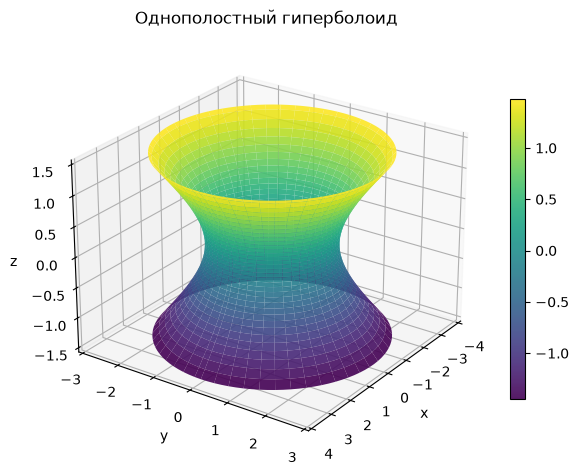

In [14]:
# Однополостный гиперболоид.

a, b, c = 2.0, 1.5, 1.0
u = np.linspace(-1.2, 1.2, 70)
v = np.linspace(0, 2 * np.pi, 100)

# TODO: создать U, V и вычислить X, Y, Z
U, V = np.meshgrid(u, v)

X = a * np.cosh(U) * np.cos(V)
Y = b * np.cosh(U) * np.sin(V)
Z = c * np.sinh(U)

# TODO: построить поверхность
fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Однополостный гиперболоид")
ax.view_init(elev=25, azim=35)
plt.colorbar(surf, ax=ax, shrink=0.65)
plt.show()

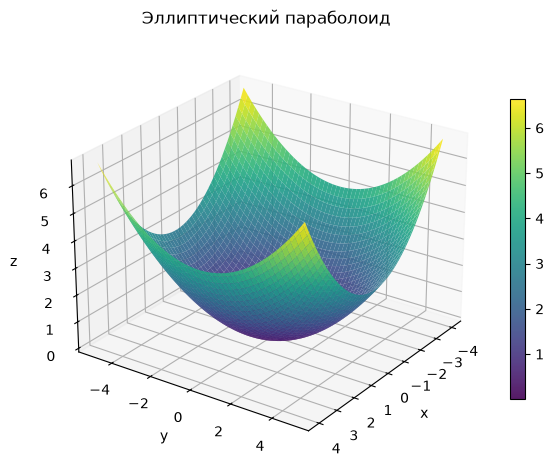

In [15]:
# Эллиптический параболоид z = x^2/4 + y^2/9.

x = np.linspace(-4, 4, 100)
y = np.linspace(-5, 5, 100)

# TODO: создать X, Y с помощью meshgrid
X, Y = np.meshgrid(x, y)

# TODO: вычислить Z
Z = X ** 2 / 4 + Y ** 2 / 9

# TODO: построить поверхность
fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Эллиптический параболоид")
ax.view_init(elev=25, azim=35)
plt.colorbar(surf, ax=ax, shrink=0.65)
plt.show()

## 6. Поверхность и линии уровня

Рассмотрим функцию

$$
f(x,y)=e^{-x^2-y^2}.
$$

Её можно представить двумя способами:

- как поверхность $z=f(x,y)$;
- как набор линий уровня $f(x,y)=C$.

Линии уровня можно интерпретировать как горизонтальные сечения поверхности. Поэтому
`contour` позволяет увидеть форму функции без трёхмерного изображения.

### Задание 7. Сравнение двух способов визуализации

На области

$$
[-2,2]\times[-2,2]
$$

постройте:

1. трёхмерную поверхность $z=e^{-x^2-y^2}$;
2. её линии уровня;
3. на контурном графике подпишите значения уровней.

После построения ответьте:

- где находится максимум функции; (0, 0, 1)
- почему линии уровня имеют такую форму; при $z = const$ логарифмируем и получаем окружности
- где поверхность наиболее крутая; ближе к пику, т.к. линии уровня сгущаются
- какую информацию легче получить из 3D-графика, а какую — из линий уровня. форму из 3д графика, значения из линий уровня

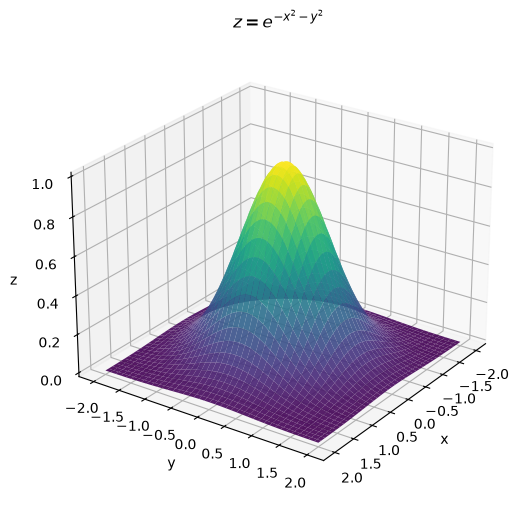

In [16]:
x = np.linspace(-2, 2, 160)
y = np.linspace(-2, 2, 160)
X, Y = np.meshgrid(x, y)
Z = np.exp(-X ** 2 - Y ** 2)

# TODO: построить 3D-поверхность
fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("$z = e^{-x^{2}-y^{2}}$")
ax.view_init(elev=25, azim=35)
plt.show()

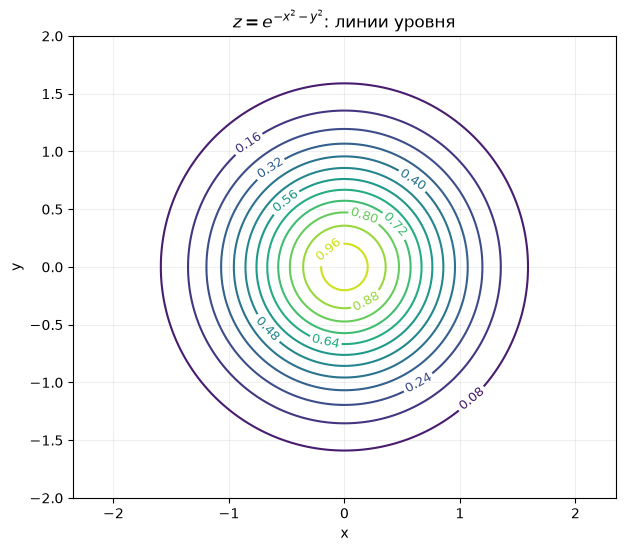

In [17]:
# TODO: построить линии уровня с помощью contour
# TODO: добавить подписи уровней с помощью clabel
plt.figure(figsize=(7, 6))
cs = plt.contour(X, Y, Z, levels=12)
plt.clabel(cs, inline=True, fontsize=9)
plt.axis("equal")
plt.grid(True, alpha=0.2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("$z = e^{-x^{2}-y^{2}}$: линии уровня")

plt.savefig("figure.png", dpi=300, bbox_inches="tight")

plt.show()

## 7. Сохранение результатов

Все основные графики, включаемые в отчёт, необходимо сохранить в формате PNG или PDF.

Для PNG используется, например:

```python
plt.savefig("figure.png", dpi=300, bbox_inches="tight")
```

Для PDF:

```python
plt.savefig("figure.pdf", bbox_inches="tight")
```

Для графиков лабораторной работы особенно важно:

- подписывать оси;
- добавлять легенду, если на графике несколько объектов;
- использовать сетку, когда она улучшает читаемость;
- сохранять правильный масштаб геометрических объектов;
- не обрезать кривые границами области построения;
- сохранять графики с разрешением не менее 300 dpi.

In [18]:
# Пример сохранения текущего графика.
# Перед сохранением убедитесь, что именно нужный график является текущим.

# plt.savefig("figure.png", dpi=300, bbox_inches="tight")
# plt.savefig("figure.pdf", bbox_inches="tight")

# Вопросы для самоконтроля

1. Почему эллипс, гиперболу и параболу удобно задавать параметрически?
2. Почему при построении гиперболы необходимо учитывать две ветви?
3. Что показывает знак $\Delta=B^2-4AC$?
4. Как член $Bxy$ связан с поворотом главных осей кривой?
5. Зачем используются однородные координаты?
6. Почему $TR$ и $RT$ в общем случае дают разные результаты?
7. Какая матрица действует первой в произведении матриц?
8. Для чего используется `np.meshgrid`?
9. Чем параметрическая поверхность отличается от поверхности вида $z=f(x,y)$?
10. Что такое линия уровня?
11. Почему для геометрических кривых важно использовать одинаковый масштаб по осям?
12. Как изменить угол обзора трёхмерного графика?
13. Почему равномерная сетка параметров не обязательно создаёт равномерное расстояние между
    соседними точками поверхности?
14. Как проверить, что построенная параметрическая кривая действительно удовлетворяет
    исходному уравнению?
15. Что означает малая невязка при построении кривой?